In [1]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt

import requests

Aquí tienes tu texto mejorado, con una redacción más fluida, técnica y profesional, manteniendo intactas todas tus ideas y explicaciones originales:

---

### **Congelamiento de Pesos (*Weight Freezing*) en Modelos de Lenguaje**

Partiendo ya del concepto de *weight tying* (que consiste en compartir o unir matrices de pesos), **congelar pesos** es una técnica sumamente familiar en el *deep learning*, especialmente aplicada durante el *fine-tuning* o el aprendizaje por transferencia. Aunque es una estrategia clásica en arquitecturas como las redes neuronales convolucionales (CNN) para visión por computadora, también podemos aplicarla en modelos de lenguaje grandes (LLMs), obteniendo una serie de ventajas potenciales muy interesantes.

A nivel de implementación, congelar una matriz de pesos es sumamente sencillo; sin embargo, puede llegar a ser abrumador sopesar la enorme cantidad de combinaciones y conjuntos de pesos posibles que se podrían congelar al realizar un ajuste fino.

#### **¿Qué significa congelar los pesos?**

Congelar los pesos significa impedir que los parámetros del modelo se modifiquen durante la retropropagación (*backpropagation*).

* Normalmente, cuando se ejecuta el *backprop*, la señal de error viaja de regreso propagándose a través de cada peso de la red.
* No obstante, si un peso está **congelado**, el sistema se salta ese parámetro y evita ajustarlo.

Esta no es una práctica deseable durante la fase inicial de preentrenamiento, pero se convierte en una técnica fundamental para el *fine-tuning*, el *transfer learning* y el *instruction tuning*. De hecho, es muy común congelar pesos en modelos de visión por computadora cuando se realiza un ajuste fino con conjuntos de datos pequeños.

#### **Ventajas principales**

Existen diversas razones por las cuales congelar los pesos resulta beneficioso:

* **Optimización de recursos:** Disminuye de forma significativa el tiempo de cálculo computacional necesario para entrenar modelos de gran escala.
* **Ajustes precisos:** Permite que las modificaciones sean mucho más específicas y sutiles sobre capas concretas.

#### **Implementación práctica en PyTorch**

En PyTorch, la gestión de los parámetros es muy sencilla gracias a un atributo llamado `requires_grad`.

* Por defecto, todos los tensores asociados a un modelo tienen esta propiedad configurada como `True`.
* Podemos simplemente cambiar este parámetro a `False`, lo que bloquea automáticamente dicho tensor y congela todos los parámetros que componen esa matriz.

In [3]:
# Cargar el modelo y el tokenizador preentrenados de GPT-2
gpt2 = AutoModelForCausalLM.from_pretrained('gpt2')
tokenizer = AutoTokenizer.from_pretrained('gpt2')

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [4]:
# hiperparámetros
seq_len = 256  # longitud máxima de secuencia
batch_size = 16

# usar GPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [5]:
# Tokenizar Los viajes de Gulliver (Gulliver's Travels)
text = requests.get('https://www.gutenberg.org/cache/epub/829/pg829.txt').text
gtTokens = tokenizer.encode(text, return_tensors='pt')[0]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (158340 > 1024). Running this sequence through the model will result in indexing errors


## Congelar los Pesos de Atención

In [8]:
for name, param in gpt2.named_parameters():
  print(name)

transformer.wte.weight
transformer.wpe.weight
transformer.h.0.ln_1.weight
transformer.h.0.ln_1.bias
transformer.h.0.attn.c_attn.weight
transformer.h.0.attn.c_attn.bias
transformer.h.0.attn.c_proj.weight
transformer.h.0.attn.c_proj.bias
transformer.h.0.ln_2.weight
transformer.h.0.ln_2.bias
transformer.h.0.mlp.c_fc.weight
transformer.h.0.mlp.c_fc.bias
transformer.h.0.mlp.c_proj.weight
transformer.h.0.mlp.c_proj.bias
transformer.h.1.ln_1.weight
transformer.h.1.ln_1.bias
transformer.h.1.attn.c_attn.weight
transformer.h.1.attn.c_attn.bias
transformer.h.1.attn.c_proj.weight
transformer.h.1.attn.c_proj.bias
transformer.h.1.ln_2.weight
transformer.h.1.ln_2.bias
transformer.h.1.mlp.c_fc.weight
transformer.h.1.mlp.c_fc.bias
transformer.h.1.mlp.c_proj.weight
transformer.h.1.mlp.c_proj.bias
transformer.h.2.ln_1.weight
transformer.h.2.ln_1.bias
transformer.h.2.attn.c_attn.weight
transformer.h.2.attn.c_attn.bias
transformer.h.2.attn.c_proj.weight
transformer.h.2.attn.c_proj.bias
transformer.h.2.ln_2

In [11]:
# Este parametro esta haciendo un bucle sobre todos los parametros h (12 bloques de transformer)

In [6]:
 for name, param in gpt2.named_parameters():
  if '.h.' in name:
    param.requires_grad = False
    print(
        f'--- La capa {name} está congelada (.requires_grad ='
        f' {param.requires_grad}).'
    )

  else:
    print(
        f'+++ La capa {name} es entrenable (.requires_grad ='
        f' {param.requires_grad}).'
    )

+++ La capa transformer.wte.weight es entrenable (.requires_grad = True).
+++ La capa transformer.wpe.weight es entrenable (.requires_grad = True).
--- La capa transformer.h.0.ln_1.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_1.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.attn.c_attn.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.attn.c_attn.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.attn.c_proj.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.attn.c_proj.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_2.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.ln_2.bias está congelada (.requires_grad = False).
--- La capa transformer.h.0.mlp.c_fc.weight está congelada (.requires_grad = False).
--- La capa transformer.h.0.mlp.c_fc.bias está congelada (.requires_grad = False).
--- La capa tran

In [13]:
# Practica solo de estudio - Se necesita una congelación mas selectiva

Basicamente todo este modelo entero esta congelado salvo las primeras y las ultimas capas. Esto no es una buena idea, no es el metodo convencional de congelacion de pesos. Sin embargo es bueno para el entendimiento del modelo.

In [20]:
# tomaremos los pesos de una capa al azar - estamos agarrando los pesos antes del fine tunning y despues de el para comparar

In [21]:
# Como verificación de sanidad, toma los pesos de una capa congelada y de otra entrenable
frozenW_pre = gpt2.transformer.h[6].mlp.c_fc.weight.data
trainW_pre = gpt2.transformer.ln_f.weight.data

In [22]:
# mover el modelo a la GPU
gpt2 = gpt2.to(device)

Optimizador

In [24]:
# Crear las funciones del optimizador
optimizer = torch.optim.AdamW(gpt2.parameters(), lr=5e-5, weight_decay=0.01)
# Nota: recordar que no se necesita la función de pérdida aquí, ya que se calcula internamente en el modelo (¡gracias HF :D!)

In [25]:
num_samples = 123
# Inicializar las pérdidas
train_loss = []
for sampli in range(num_samples):

  # Obtener un lote de datos
  ix = torch.randint(len(gtTokens) - seq_len, size=(batch_size,))
  X = gtTokens[ix[:, None] + torch.arange(seq_len)].to(device)

  # Pasada hacia adelante (Hugging Face desplaza X internamente para obtener y)
  gpt2.zero_grad()
  outputs = gpt2(X, labels=X)
  loss = outputs.loss

  # Retropropagación
  loss.backward()
  optimizer.step()

  # Almacenar la pérdida por muestra
  train_loss.append(loss.item())

  # Actualizar la visualización del progreso
  if sampli % 27 == 0:
    print(
        f'Muestra {sampli:4}/{num_samples}, pérdida de entrenamiento:'
        f' {train_loss[-1]:.4f}'
    )

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Muestra    0/123, pérdida de entrenamiento: 5.4330
Muestra   27/123, pérdida de entrenamiento: 5.1799
Muestra   54/123, pérdida de entrenamiento: 4.8925
Muestra   81/123, pérdida de entrenamiento: 4.7319
Muestra  108/123, pérdida de entrenamiento: 4.5516


In [28]:
# El objetivo es ver la tecnica y no ajustar el modelo

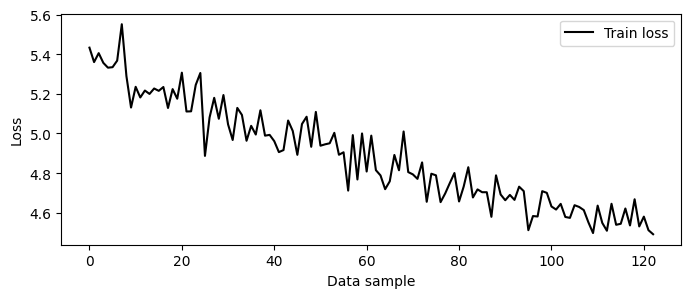

In [26]:
# Graficar los errores
plt.figure(figsize=(8,3))
plt.plot(train_loss,'k',markersize=8,label='Train loss')

plt.legend()
plt.gca().set(xlabel='Data sample',ylabel='Loss')
plt.show()

In [29]:
# Volver a capturar las matrices de pesos (después del entrenamiento)
frozenW_pst = gpt2.transformer.h[6].mlp.c_fc.weight.data.cpu()
trainW_pst = gpt2.transformer.ln_f.weight.data.cpu()

La norma de una matriz de ceros es cero

In [36]:
# Debería ser todo ceros si la capa fue congelada
print('Capa congelada, norma(post-pre):')
print('  ', torch.norm(frozenW_pst.cpu() - frozenW_pre.cpu()))

#print('\nCapa entrenable, norma(post-pre):')
#print('  ', torch.norm(trainW_pst.cpu() - trainW_pre.cpu()))

Capa congelada, norma(post-pre):
   tensor(0.)


### Para comprobación

In [37]:
# Para realizar la comprobación real de forma correcta:
# 1. Volvemos a instanciar el modelo gpt2_check para tener pesos limpios
gpt2_check = AutoModelForCausalLM.from_pretrained('gpt2')

# 2. Congelamos las capas intermedias como antes
for name, param in gpt2_check.named_parameters():
  if '.h.' in name:
    param.requires_grad = False

# 3. Guardamos copias FÍSICAS usando .clone().cpu()
frozenW_pre_correct = gpt2_check.transformer.h[6].mlp.c_fc.weight.data.clone().cpu()
trainW_pre_correct = gpt2_check.transformer.ln_f.weight.data.clone().cpu()

# 4. Movemos a GPU y entrenamos en un solo lote rápido para actualizar parámetros
gpt2_check = gpt2_check.to(device)
opt = torch.optim.AdamW(gpt2_check.parameters(), lr=1e-3)

ix = torch.randint(len(gtTokens) - seq_len, size=(batch_size,))
X = gtTokens[ix[:, None] + torch.arange(seq_len)].to(device)

gpt2_check.zero_grad()
loss = gpt2_check(X, labels=X).loss
loss.backward()
opt.step()

# 5. Capturamos los pesos después del entrenamiento
frozenW_pst_correct = gpt2_check.transformer.h[6].mlp.c_fc.weight.data.clone().cpu()
trainW_pst_correct = gpt2_check.transformer.ln_f.weight.data.clone().cpu()

# 6. Evaluamos las diferencias
print('Capa congelada, norma real (post - pre):')
print('  ', torch.norm(frozenW_pst_correct - frozenW_pre_correct).item())

print('\nCapa entrenable, norma real (post - pre):')
print('  ', torch.norm(trainW_pst_correct - trainW_pre_correct).item())

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Capa congelada, norma real (post - pre):
   0.0

Capa entrenable, norma real (post - pre):
   0.02792540192604065


---

### **¿Por qué congelar los pesos? Motivaciones y ventajas clave**

Existen diversas razones de gran peso por las cuales aplicar esta técnica resulta fundamental:

* **Mitigación del *overfitting* y control de idiosincrasias:** Al entrenar solo una fracción de los parámetros, se reduce drásticamente el riesgo de sobreajuste. Esto es vital cuando no se desea que el modelo absorba peculiaridades o idiosincrasias excesivas del conjunto de datos de entrenamiento (a diferencia de nuestro ejemplo anterior con Alice y Edgar, donde justamente buscábamos adaptarnos a un estilo literario muy específico).


* **Adaptación con conjuntos de datos limitados:** Al trabajar con volúmenes de datos pequeños en comparación con el preentrenamiento masivo —como adaptar un modelo base a la documentación técnica interna de una empresa—, congelar la mayor parte de la red ayuda a que el modelo se adapte mejor sin alterar las bases de su conocimiento general.


* **Eficiencia de costos y recursos (Viabilidad práctica):** Los LLM modernos manejan miles de millones o incluso billones de parámetros. Afinar un modelo de esa escala demanda una inversión altísima en tiempo, dinero y recursos computacionales, por lo que congelar grandes secciones se vuelve indispensable para hacerlo factible con hardware limitado.


* **Congelación selectiva (*Targeted Freezing*):** Permite aprovechar la jerarquía interna de los transformadores. Las capas anteriores suelen especializarse en sintaxis y semántica de bajo nivel (la estructura básica del lenguaje), mientras que las capas posteriores capturan contexto de alto nivel y patrones abstractos. Congelar la primera mitad de los bloques preserva las bases sintácticas, enfocando el entrenamiento únicamente en las características superiores (una estrategia muy útil, por ejemplo, al entrenar modelos de clasificación de textos).

---

### **El abanico de posibilidades: Estrategias avanzadas de congelación**

La flexibilidad de esta técnica abre una verdadera explosión de posibilidades sobre **qué capas específicas elegir para congelar** según el objetivo que busquemos:

* **Manipulación selectiva de componentes:** Por ejemplo, si congelamos por completo todas las capas de las redes de alimentación directa (*MLP*), permitimos que únicamente las capas de atención sigan ajustándose. Esto puede modificar de forma preferencial cómo se relacionan y ponderan los tokens a lo largo del tiempo.
* **Preservación del conocimiento base:** Congelar los bloques principales de los transformadores permite que el entrenamiento se centre en características textuales y contextuales de alto nivel, preservando al mismo tiempo la base del conocimiento semántico y sintáctico general.
* **Estrategias dinámicas de descongelación (*Unfreezing*):** Es posible congelar una capa al inicio de la sintonización y descongelarla más adelante (por ejemplo, tras procesar las primeras 100 muestras de entrenamiento). Otra alternativa es monitorear la función de pérdida (*loss*) durante el *fine-tuning* y liberar ciertas capas de forma automatizada cuando la pérdida caiga por debajo de un umbral preestablecido.
* **Investigación e interpretación mecanicista:** Más allá de su utilidad práctica para ahorrar recursos, la congelación selectiva se emplea ampliamente en la investigación para poner a prueba hipótesis y entender con precisión qué aprenden las distintas partes y subcomponentes de la arquitectura de un modelo.

In [38]:
# la implementacion de congelar pesos es facil- pero dificil tambien porque implica mucha experimentacion de que y cuando , y puede llevar bastante tiempo